In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Criei funções de todas as fórmulas que serão utilizadas

In [47]:
def media_estimativas(estimativas):

    return np.mean(estimativas)

def vies_empirico(estimativas, theta_0):

    return media_estimativas(estimativas) - theta_0

def variancia_empirica(estimativas):
   
    return np.var(estimativas)

def eqm_empirico(estimativas, theta_0):
   
    estimativas_array = np.array(estimativas)
    return np.mean((estimativas_array - theta_0)**2)

Criando a seed e definindo os parâmetros verdadeiros

In [48]:
np.random.seed(99)
mi = 5
sigma2 = 1
n_50 = 50

(array([2., 0., 1., 2., 3., 5., 6., 9., 4., 6., 6., 1., 1., 2., 2.]),
 array([2.63216241, 2.93717228, 3.24218216, 3.54719204, 3.85220192,
        4.1572118 , 4.46222168, 4.76723156, 5.07224144, 5.37725131,
        5.68226119, 5.98727107, 6.29228095, 6.59729083, 6.90230071,
        7.20731059]),
 <BarContainer object of 15 artists>)

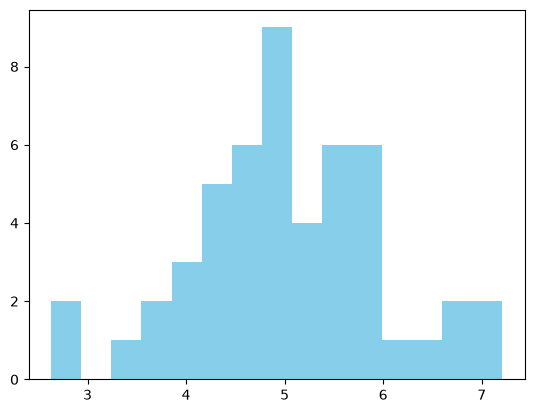

In [49]:
amostra_normal_50 = np.random.normal(mi,sigma2,n_50)
plt.hist(amostra_normal_50,bins=15,color="skyblue")

Sabemos que pelo método da verssimilhança o estimador para a média é a média amostral e para a variância é a variância amostral dividida por n

In [50]:
mi_mmv_50 = sum(amostra_normal_50)/n_50
var_mmv_50 = np.var(amostra_normal_50)
print(f'Os estimadores de máxima verossimilhança para a média e a variância são, respectivamente {mi_mmv_50} e {var_mmv_50}')

Os estimadores de máxima verossimilhança para a média e a variância são, respectivamente 5.004149728475859 e 0.9438127190801978


Aqui geramos as 9 amostras das normais com mi = 5 e sigma2 = 1 de tamanho 50.

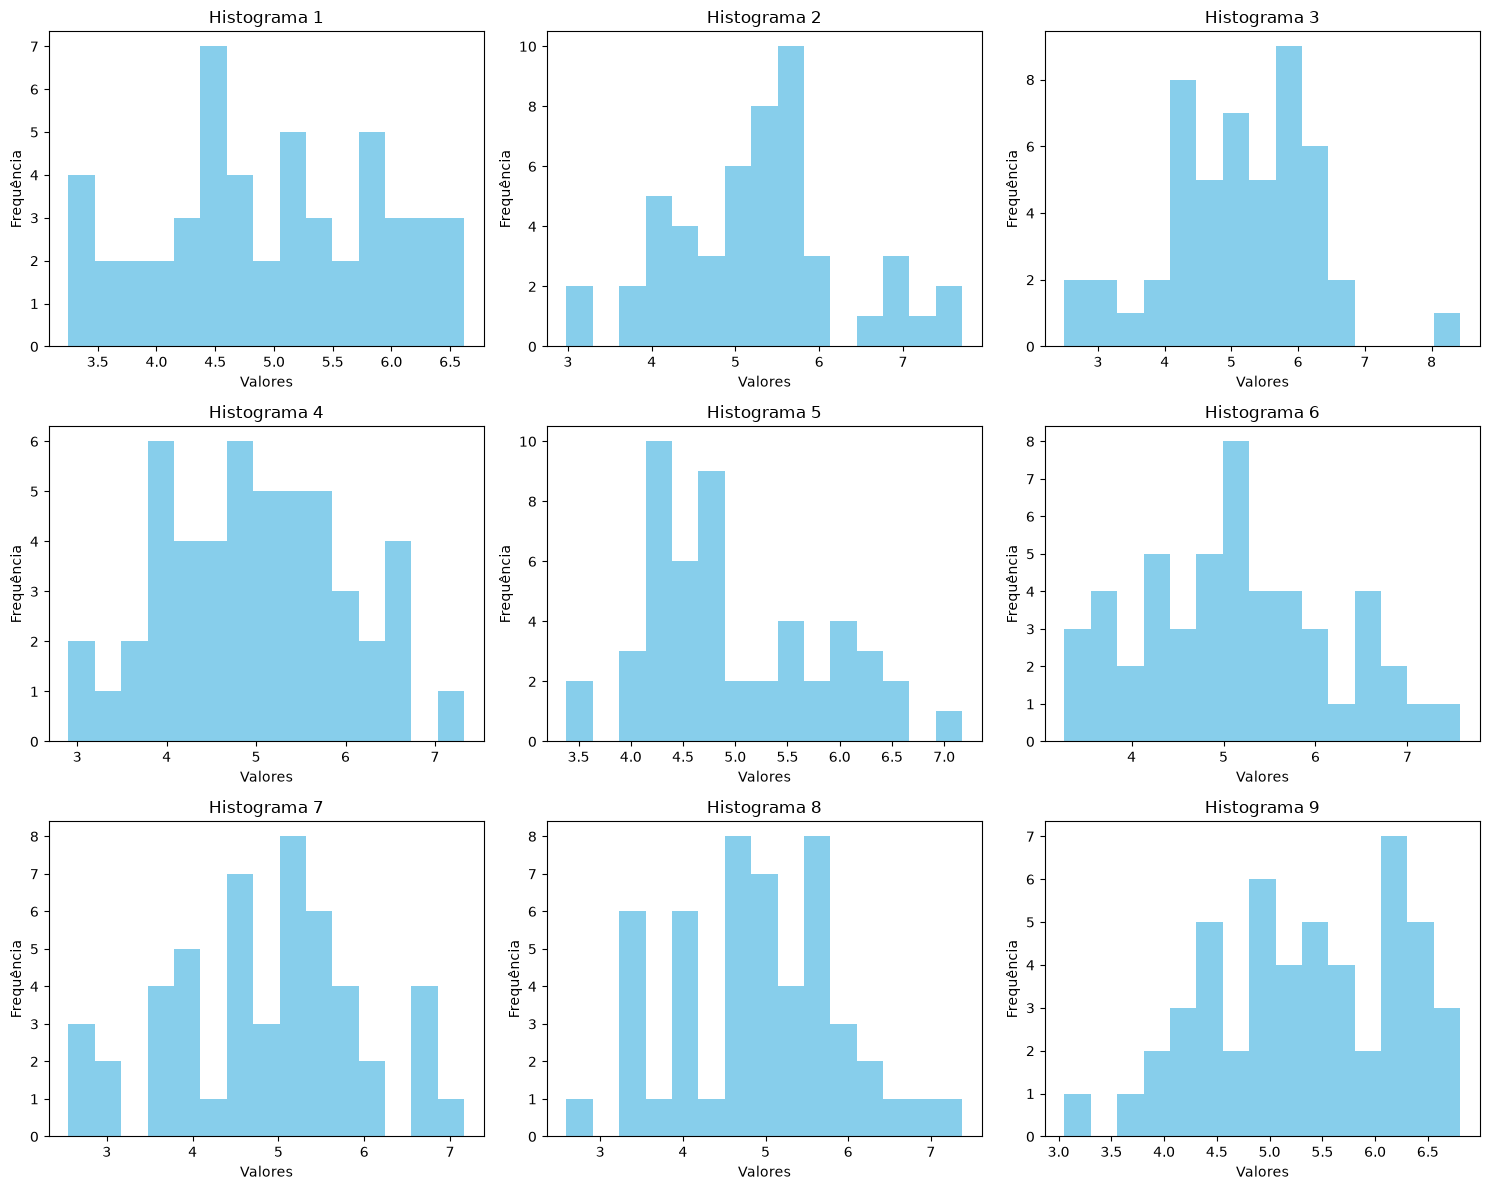

In [51]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
medias = [mi_mmv_50]
vars = [var_mmv_50]
axes = axes.flatten()

for i in range(9):
    np.random.seed(100 + i)
    

    dados = np.random.normal(5, 1,size= n_50)
    media = np.mean(dados)
    var = np.var(dados)
    medias.append(media)
    vars.append(var)
    

    axes[i].hist(dados, bins=15, color='skyblue')
    
    axes[i].set_title(f'Histograma {i+1}')
    axes[i].set_xlabel('Valores')
    axes[i].set_ylabel('Frequência')


plt.tight_layout()


plt.show() 

Aqui fizemos as tabelas com as médias e variâncias de cada amostra.

In [52]:
nomes_amostras = [f'{i+1}ª Amostra' for i in range(len(medias))]
tabela = pd.DataFrame({
    'Médias': medias,
    'Variâncias': vars,
}, index=nomes_amostras)
tabela


,Médias,Variâncias
1ª Amostra,5.004150,0.943813
2ª Amostra,4.959199,0.885895
3ª Amostra,5.268114,1.054789
4ª Amostra,5.097030,1.240000
5ª Amostra,4.999974,1.005902
6ª Amostra,4.982601,0.699685
7ª Amostra,5.132228,1.098582
8ª Amostra,4.830735,1.193433
9ª Amostra,4.899121,0.964909
10ª Amostra,5.315679,0.807212


Aqui calculamos as estimativas para a média e variância.

In [53]:
# Média das estimativas
media_medias = media_estimativas(medias)
media_variancias = media_estimativas(vars)

# Viéses empíricos
vies_emp_medias = vies_empirico(medias, 5)
vies_emp_variancias = vies_empirico(vars, 1)

# Variâncias empíricas
var_emp_medias = variancia_empirica(medias)
var_emp_variancias = variancia_empirica(vars)

# EQM empírico
eqm_emp_medias = eqm_empirico(medias, 5)
eqm_emp_var = eqm_empirico(vars, 1)


# EQM = Variancias empiricas + vieses^2
eqm_formula_medias = var_emp_medias + vies_emp_medias**2
eqm_formula_variancias = var_emp_variancias + vies_emp_variancias**2

Aqui criamos as tabelas com as estimativas

In [54]:
dados_tabela = {
    'Média das Estimativas': [media_medias, media_variancias],
    'Viés Empírico': [vies_emp_medias, vies_emp_variancias],
    'Variância Empírica': [var_emp_medias, var_emp_variancias],
    'EQM Empírico': [eqm_emp_medias, eqm_emp_var],
    'EQM Fórmula': [eqm_formula_medias, eqm_formula_variancias],
    'Valor Verdadeiro' : [mi, sigma2]
}

# Cria o DataFrame definindo os nomes das linhas (índices)
tabela_resultados = pd.DataFrame(
    dados_tabela, 
    index=['Estimativas da Média (μ)', 'Estimativas da Variância (σ²)']
)
tabela_resultados

,Média das Estimativas,Viés Empírico,Variância Empírica,EQM Empírico,EQM Fórmula,Valor Verdadeiro
Estimativas da Média (μ),5.048883,0.048883,0.021535,0.023925,0.023925,5
Estimativas da Variância (σ²),0.989422,-0.010578,0.025142,0.025254,0.025254,1


In [55]:
# ==========================================
# EXPORTANDO AS TABELAS PARA CÓDIGO LATEX
# ==========================================

# Exporta a tabela de resultados gerais
# index=True é importante aqui para manter os nomes das linhas (Média, Variância)
tabela_resultados.to_latex('tabela_resultados.tex', index=True, float_format="%.4f")

# Exporta a tabela com as 10 amostras
tabela.to_latex('tabela_amostras.tex', index=True, float_format="%.4f")


# ==========================================
# EXPORTANDO OS GRÁFICOS PARA PDF
# ==========================================

# Salvando a grade de 9 histogramas (coloque isso ANTES do plt.show() do primeiro gráfico)
fig.savefig('grade_histogramas.pdf', bbox_inches='tight')

# Para o último histograma (amostra_normal_50), adicione isso ANTES do plt.show() dele:
# plt.figure() # Certifique-se de iniciar a figura se ela estiver sendo sobreposta
# plt.hist(amostra_normal_50, bins=15, color="skyblue")
plt.savefig('histograma_50.pdf', bbox_inches='tight')

print("Arquivos exportados com sucesso!")

Arquivos exportados com sucesso!


<Figure size 640x480 with 0 Axes>

Quando olhamos para o viés teórico do estimador X barra (média amostral), sabemos que ele é não viesado, mas quando olhamos para a estimativa, o viés pode sim aparecer

(array([ 2.,  3., 11., 22., 35., 41., 34., 27., 16.,  9.]),
 array([2.43994051, 2.90740107, 3.37486163, 3.84232219, 4.30978274,
        4.7772433 , 5.24470386, 5.71216441, 6.17962497, 6.64708553,
        7.11454609]),
 <BarContainer object of 10 artists>)

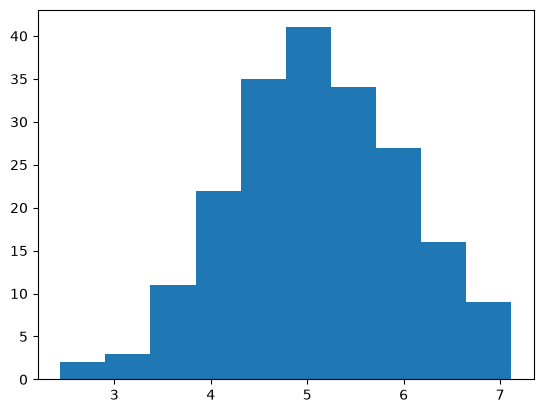

In [56]:
n_200 = 200
amostra_normal_200 = np.random.normal(5,1,size = n_200)
plt.hist(amostra_normal_200)